# Diabetes Health Indicators: Binary Classification

## Problem
Can health, lifestyle, and demographic survey indicators classify a respondent's `Diabetes_binary` label? This notebook explores the data, compares baseline and tuned classifiers, and evaluates a final XGBoost model on a held-out test set.

## Dataset
The analysis uses `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` from the [Kaggle Diabetes Health Indicators dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset), based on CDC BRFSS survey data. The selected file contains 70,692 rows, 21 features, and one target column. It is a balanced 50/50 subset, so its class distribution does not represent the original survey population.

The UCI dataset documentation defines `Diabetes_binary = 0` as no diabetes and `Diabetes_binary = 1` as prediabetes or diabetes. See [CDC Diabetes Health Indicators](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators) for variable descriptions.

## Workflow
1. Load and validate the data.
2. Explore target balance, feature distributions, and univariate associations.
3. Split the data into training, validation, and test sets.
4. Compare classifiers using validation ROC AUC and tune selected hyperparameters.
5. Train the selected XGBoost model on training plus validation data, evaluate once on the test set, and save the model artifact.

In [38]:
import pickle
from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import xgboost as xgb
import kagglehub


from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score, roc_auc_score, classification_report, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier


import warnings
warnings.filterwarnings('ignore')

%matplotlib inline 

## Data preparation and exploratory analysis

Download the selected balanced CSV from Kaggle, then check its schema, missing values, target distribution, and feature relationships. KaggleHub caches the downloaded dataset locally, so later runs can reuse the cached copy.

In [2]:


# Download the dataset from Kaggle
dataset_path = Path(kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset"))
csv_path = dataset_path / "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"

print(f"Dataset downloaded to: {dataset_path}")
df = pd.read_csv(csv_path)
df.head().T

Dataset downloaded to: C:\Users\Teeplus\.cache\kagglehub\datasets\alexteboul\diabetes-health-indicators-dataset\versions\1


,0,1,2,3,4
Diabetes_binary,0.0,0.0,0.0,0.0,0.0
HighBP,1.0,1.0,0.0,1.0,0.0
HighChol,0.0,1.0,0.0,1.0,0.0
CholCheck,1.0,1.0,1.0,1.0,1.0
BMI,26.0,26.0,26.0,28.0,29.0
Smoker,0.0,1.0,0.0,1.0,1.0
Stroke,0.0,1.0,0.0,0.0,0.0
HeartDiseaseorAttack,0.0,0.0,0.0,0.0,0.0
PhysActivity,1.0,0.0,1.0,1.0,1.0
Fruits,0.0,1.0,1.0,1.0,1.0


In [3]:
# checking the shape of the dataset
print(f"Dataset shape: {df.shape}")

df.columns.tolist()

Dataset shape: (70692, 22)


['Diabetes_binary',
 'HighBP',
 'HighChol',
 'CholCheck',
 'BMI',
 'Smoker',
 'Stroke',
 'HeartDiseaseorAttack',
 'PhysActivity',
 'Fruits',
 'Veggies',
 'HvyAlcoholConsump',
 'AnyHealthcare',
 'NoDocbcCost',
 'GenHlth',
 'MentHlth',
 'PhysHlth',
 'DiffWalk',
 'Sex',
 'Age',
 'Education',
 'Income']

In [4]:
df.columns = df.columns.str.lower()

In [5]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
diabetes_binary         0
highbp                  0
highchol                0
cholcheck               0
bmi                     0
smoker                  0
stroke                  0
heartdiseaseorattack    0
physactivity            0
fruits                  0
veggies                 0
hvyalcoholconsump       0
anyhealthcare           0
nodocbccost             0
genhlth                 0
menthlth                0
physhlth                0
diffwalk                0
sex                     0
age                     0
education               0
income                  0
dtype: int64


In [6]:
numerical = ["bmi", "menthlth", "physhlth"]

categorical = [col for col in df.columns if col not in numerical + ["diabetes_binary"]]

In [7]:
#Number of unique values per column
df[categorical].nunique()

highbp                   2
highchol                 2
cholcheck                2
smoker                   2
stroke                   2
heartdiseaseorattack     2
physactivity             2
fruits                   2
veggies                  2
hvyalcoholconsump        2
anyhealthcare            2
nodocbccost              2
genhlth                  5
diffwalk                 2
sex                      2
age                     13
education                6
income                   8
dtype: int64

,count,percent
diabetes_binary,,
0.0,35346,50.0
1.0,35346,50.0


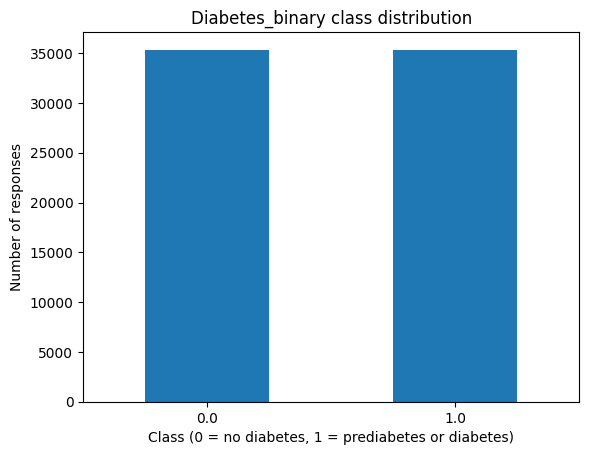

In [8]:
# Target variable summary
target_counts = df["diabetes_binary"].value_counts().sort_index()
target_summary = target_counts.to_frame("count")
target_summary["percent"] = 100 * target_counts / len(df)

display(target_summary.round(2))

target_counts.plot(kind="bar", rot=0)
plt.title("Diabetes_binary class distribution")
plt.xlabel("Class (0 = no diabetes, 1 = prediabetes or diabetes)")
plt.ylabel("Number of responses")
plt.show()

In [9]:
df[numerical].describe().round(2)

,bmi,menthlth,physhlth
count,70692.00,70692.00,70692.00
mean,29.86,3.75,5.81
std,7.11,8.16,10.06
min,12.00,0.00,0.00
25%,25.00,0.00,0.00
50%,29.00,0.00,0.00
75%,33.00,2.00,6.00
max,98.00,30.00,30.00


bmi                          menthlth                   \
                median   mean   std   min   max   median  mean   std  min   
diabetes_binary                                                             
0.0               27.0  27.77  6.19  12.0  98.0      0.0  3.04  7.21  0.0   
1.0               31.0  31.94  7.36  13.0  98.0      0.0  4.46  8.95  0.0   

                      physhlth                         
                  max   median  mean   std  min   max  
diabetes_binary                                        
0.0              30.0      0.0  3.67   8.1  0.0  30.0  
1.0              30.0      1.0  7.95  11.3  0.0  30.0

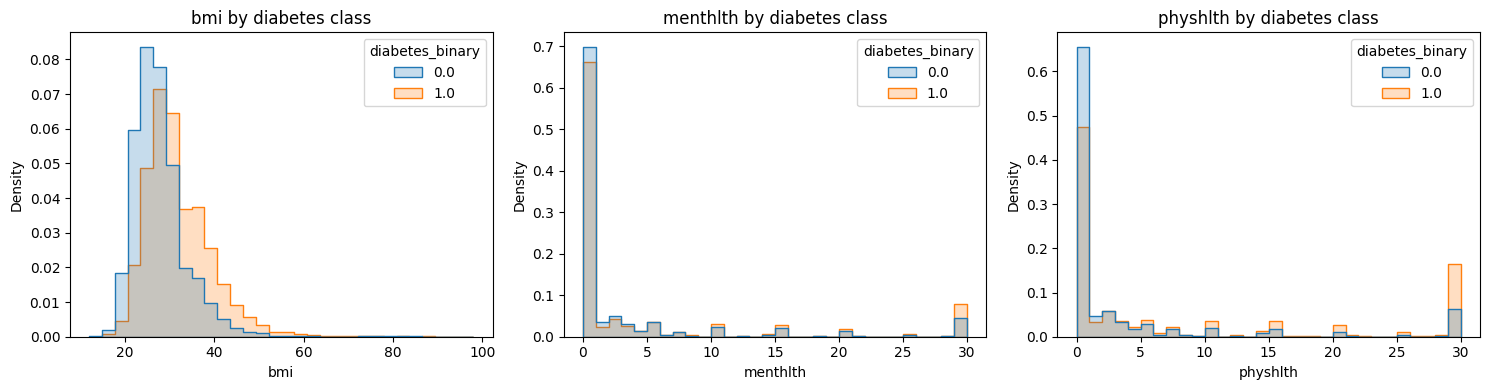

In [10]:
display(
    df.groupby("diabetes_binary")[numerical]
      .agg(["median", "mean", "std", "min", "max"])
      .round(2)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, numerical):
    sns.histplot(
        data=df, x=feature, hue="diabetes_binary",
        bins=30, stat="density", common_norm=False,
        element="step", ax=ax
    )
    ax.set_title(f"{feature} by diabetes class")

plt.tight_layout()
plt.show()

,Class 0.0,Class 1.0
highbp,0.374,0.753
highchol,0.381,0.670
cholcheck,0.957,0.993
smoker,0.432,0.518
stroke,0.032,0.092
heartdiseaseorattack,0.073,0.223
physactivity,0.776,0.631
fruits,0.638,0.585
veggies,0.821,0.756
hvyalcoholconsump,0.062,0.024


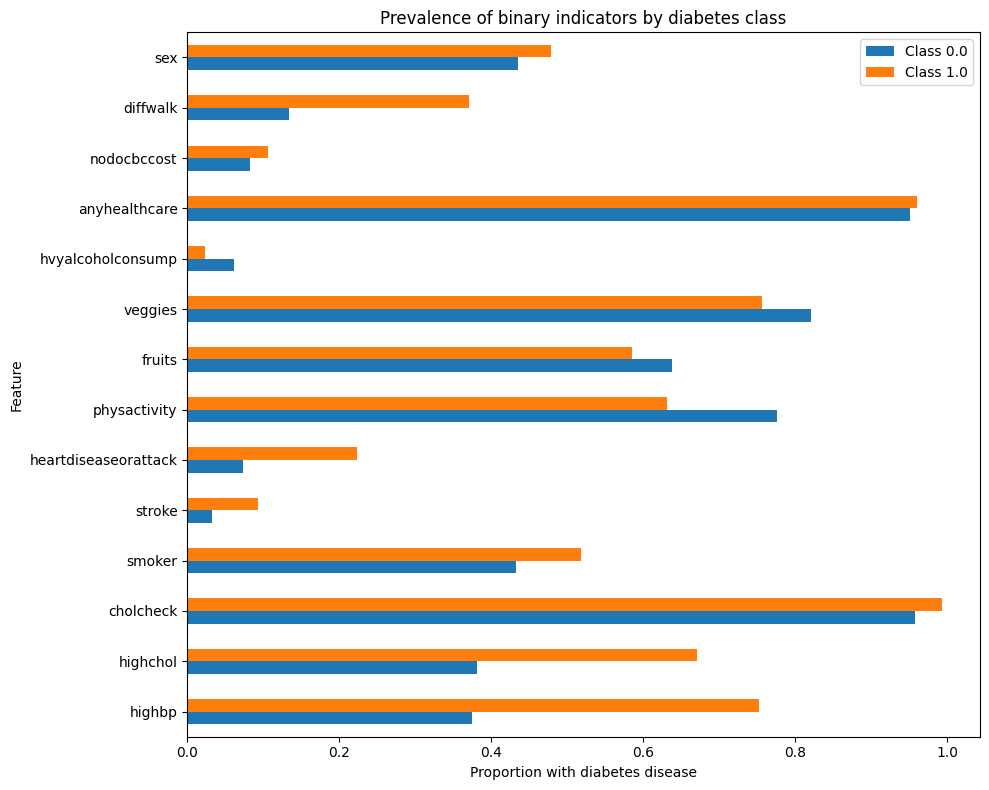

In [11]:
target_col = "diabetes_binary"

binary_features = [
    col for col in df.columns
    if col != target_col
    and col.lower() not in {"id", "index"}
    and set(df[col].dropna().unique()).issubset({0, 1})
    and df[col].nunique() == 2
]

rates = df.groupby(target_col)[binary_features].mean().T
rates.columns = [f"Class {value}" for value in rates.columns]

display(rates.round(3))

rates.plot(kind="barh", figsize=(10, 8))
plt.title("Prevalence of binary indicators by diabetes class")
plt.xlabel("Proportion with diabetes disease")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [12]:
coded_features = ["age", "education", "income", "genhlth"]

for feature in coded_features:
    proportions = pd.crosstab(
        df[feature],
        df["diabetes_binary"],
        normalize="index"
    )
    proportions = proportions.rename(
        columns={0: "Class 0 proportion", 1: "Class 1 proportion"}
    )

    print(f"\n{feature}: proportion in each diabetes class")
    display(proportions.round(3))


age: proportion in each diabetes class


diabetes_binary,Class 0 proportion,Class 1 proportion
age,,
1.0,0.920,0.080
2.0,0.900,0.100
3.0,0.847,0.153
4.0,0.776,0.224
5.0,0.701,0.299
6.0,0.625,0.375
7.0,0.551,0.449
8.0,0.504,0.496
9.0,0.433,0.567



education: proportion in each diabetes class


diabetes_binary,Class 0 proportion,Class 1 proportion
education,,
1.0,0.373,0.627
2.0,0.282,0.718
3.0,0.334,0.666
4.0,0.432,0.568
5.0,0.483,0.517
6.0,0.600,0.400



income: proportion in each diabetes class


diabetes_binary,Class 0 proportion,Class 1 proportion
income,,
1.0,0.340,0.660
2.0,0.314,0.686
3.0,0.358,0.642
4.0,0.391,0.609
5.0,0.438,0.562
6.0,0.486,0.514
7.0,0.539,0.461
8.0,0.652,0.348



genhlth: proportion in each diabetes class


diabetes_binary,Class 0 proportion,Class 1 proportion
genhlth,,
1.0,0.862,0.138
2.0,0.679,0.321
3.0,0.426,0.574
4.0,0.264,0.736
5.0,0.212,0.788


## Exploratory analysis

Compare feature distributions and target rates across the two classes.

### Feature associations

In [13]:
global_diabetes_binary = df.diabetes_binary.mean()

In [14]:
binary_rates = df.groupby(target_col)[binary_features].mean().T
binary_rates.columns = ["No diabetes (0)", "Prediabetes or diabetes (1)"]
binary_rates["rate_difference"] = (
    binary_rates["Prediabetes or diabetes (1)"] - binary_rates["No diabetes (0)"]
)
display(binary_rates.sort_values("rate_difference", ascending=False).round(3))

,No diabetes (0),Prediabetes or diabetes (1),rate_difference
highbp,0.374,0.753,0.378
highchol,0.381,0.670,0.289
diffwalk,0.134,0.371,0.237
heartdiseaseorattack,0.073,0.223,0.150
smoker,0.432,0.518,0.086
stroke,0.032,0.092,0.061
sex,0.435,0.479,0.044
cholcheck,0.957,0.993,0.036
nodocbccost,0.082,0.106,0.024
anyhealthcare,0.950,0.960,0.010


Next, compare univariate feature associations and evaluate models on held-out data.

In [15]:
def mutual_info_diabetes_score(series):
    return mutual_info_score(series, df["diabetes_binary"])


In [16]:
# Mutual information is a univariate association measure, not model feature importance.
mi = df[categorical].apply(mutual_info_diabetes_score)
mi.sort_values(ascending=False).to_frame("mutual_information")

,mutual_information
genhlth,0.092682
highbp,0.074794
age,0.046827
highchol,0.042432
diffwalk,0.038327
income,0.027702
heartdiseaseorattack,0.023294
education,0.015269
physactivity,0.012684
stroke,0.008190


In [17]:
#Correlation of numerical features with diabetes_binary

df[numerical].corrwith(df.diabetes_binary)

bmi         0.293373
menthlth    0.087029
physhlth    0.213081
dtype: float64

In [18]:
# rank features by importance
df[numerical].corrwith(df.diabetes_binary).abs().sort_values(ascending=False)

bmi         0.293373
physhlth    0.213081
menthlth    0.087029
dtype: float64

## Train, validation, and test split

Use stratified splits to preserve the balanced target distribution. Reserve the test set for the final evaluation; use the training and validation sets for model comparison and tuning.

In [19]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42,
    stratify=df["diabetes_binary"]
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=42,
    stratify=df_full_train["diabetes_binary"]
)  # 0.25 x 0.8 = 0.2
len(df_train), len(df_val), len(df_test)

(42414, 14139, 14139)

In [20]:
#reset index for all datasets
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [21]:
#target variable

y_train = df_train.diabetes_binary.values
y_val = df_val.diabetes_binary.values
y_test = df_test.diabetes_binary.values

del df_train['diabetes_binary']
del df_val['diabetes_binary']
del df_test['diabetes_binary']

In [22]:
#one-hot encoding for categorical features
dv = DictVectorizer(sparse=False)
# Convert categorical values to strings so DictVectorizer one-hot encodes them;
# numeric features remain numeric.
def to_feature_dicts(frame):
    features = frame.copy()
    features[categorical] = features[categorical].astype(str)
    return features.to_dict(orient="records")

train_dicts = to_feature_dicts(df_train)
val_dicts = to_feature_dicts(df_val)
test_dicts = to_feature_dicts(df_test)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

### Logistic regression baseline

In [23]:
lgr = LogisticRegression(max_iter=1000, random_state=42)
lgr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [25]:
y_pred_val = lgr.predict_proba(X_val)[:, 1]

diabetes_predictions = (y_pred_val >= 0.5).astype(int)
print("Validation accuracy:", round((y_val == diabetes_predictions).mean(), 3))

Validation accuracy: 0.75


In [30]:
print("Validation ROC AUC:", round(roc_auc_score(y_val, y_pred_val), 3))

print("-" * 55)

# 2. Generate Classification Report (Uses the 0/1 predictions)
# target_names maps 0 and 1 to readable categories
print("Classification Report:")
print(classification_report(y_val, diabetes_predictions, target_names=["No Diabetes (0)", "Diabetes (1)"]))

Validation ROC AUC: 0.828
-------------------------------------------------------
Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.76      0.72      0.74      7069
   Diabetes (1)       0.74      0.78      0.76      7070

       accuracy                           0.75     14139
      macro avg       0.75      0.75      0.75     14139
   weighted avg       0.75      0.75      0.75     14139



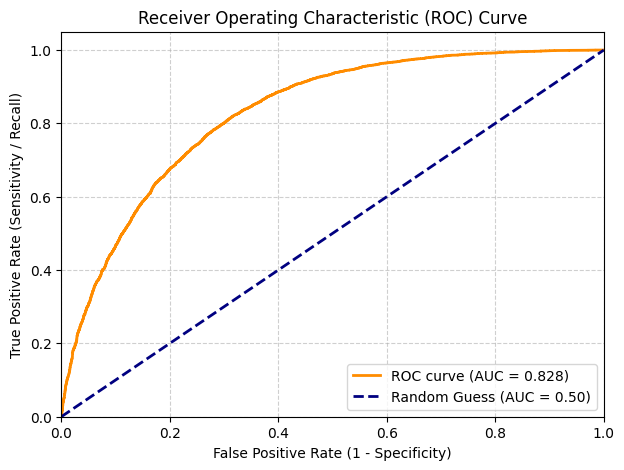

In [ ]:


# Calculate false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(y_val, y_pred_val)
roc_auc = roc_auc_score(y_val, y_pred_val)

# Plot the ROC Curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.50)')

# Formatting the plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [35]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Create a grid search to find the best regularization strength (C)
# using ROC AUC, evaluated with the stratified cross-validation splits.
grid_search = GridSearchCV(
    LogisticRegression(solver="liblinear", max_iter=1000, random_state=42),
    param_grid=param_grid,  # Values of C to test
    scoring="roc_auc",      # Select the model with the highest ROC AUC
    cv=cv,                  
    n_jobs=-1,              
)

grid_search.fit(X_train, y_train)

tuned_lgr = grid_search.best_estimator_
val_probabilities = tuned_lgr.predict_proba(X_val)[:, 1]

diabetes_predictions = (val_probabilities >= 0.5).astype(int)
validation_accuracy = (y_val == diabetes_predictions).mean()

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation ROC AUC:", round(grid_search.best_score_, 4))
print("Validation Accuracy:", round(validation_accuracy, 4))

Best parameters: {'C': 0.1}
Best cross-validation ROC AUC: 0.8263
Validation Accuracy: 0.7499


In [36]:
train_auc = roc_auc_score(y_train, tuned_lgr.predict_proba(X_train)[:, 1])
val_auc = roc_auc_score(y_val, tuned_lgr.predict_proba(X_val)[:, 1])
print("Training ROC AUC (Tuned Logistic Regression):", round(train_auc, 4))
print("Validation ROC AUC (Tuned Logistic Regression):", round(val_auc, 4))

Training ROC AUC (Tuned Logistic Regression): 0.8271
Validation ROC AUC (Tuned Logistic Regression): 0.8278


### Decision tree

In [39]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [40]:
y_pred_val_dt = dt.predict_proba(X_val)[:, 1]
print("Validation ROC AUC (Decision Tree):", round(roc_auc_score(y_val, y_pred_val_dt), 4))

Validation ROC AUC (Decision Tree): 0.658


In [41]:
#Selecting max_depth
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths: 
    dt = DecisionTreeClassifier(random_state=42, max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.694
   2 -> 0.735
   3 -> 0.767
   4 -> 0.787
   5 -> 0.797
   6 -> 0.804
  10 -> 0.796
  15 -> 0.731
  20 -> 0.678
None -> 0.658


In [42]:
#Adding min_samples_leaf

scores = []

for depth in [5, 6, 10]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(random_state=42, max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

In [43]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

In [44]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc              
max_depth            5      6      10
min_samples_leaf                     
1                 0.797  0.804  0.796
5                 0.797  0.804  0.802
10                0.797  0.803  0.805
15                0.797  0.804  0.807
20                0.797  0.803  0.806
100               0.797  0.803  0.809
200               0.797  0.803  0.808
500               0.796  0.803  0.806

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

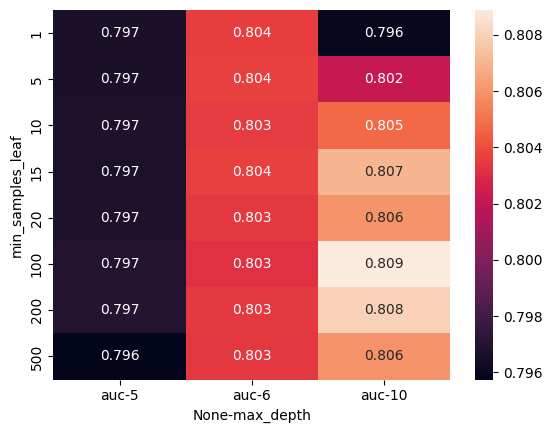

In [45]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

In [46]:
best_tree_row = df_scores.loc[df_scores["auc"].idxmax()]
depth = int(best_tree_row["max_depth"])
min_samples_leaf = int(best_tree_row["min_samples_leaf"])
print("Selected tree parameters:", {"max_depth": depth, "min_samples_leaf": min_samples_leaf})

Selected tree parameters: {'max_depth': 10, 'min_samples_leaf': 100}


In [47]:
# Fit and evaluate the selected decision tree using validation ROC AUC.
tuned_dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=depth,
    min_samples_leaf=min_samples_leaf,
)
tuned_dt.fit(X_train, y_train)

y_pred_dt = tuned_dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred_dt)
print("Validation ROC AUC (Tuned Decision Tree):", round(auc, 4))

Validation ROC AUC (Tuned Decision Tree): 0.8089


In [48]:
train_auc = roc_auc_score(y_train, tuned_dt.predict_proba(X_train)[:, 1])
print("Training ROC AUC (Tuned Decision Tree):", round(train_auc, 4))

Training ROC AUC (Tuned Decision Tree): 0.8227


### Random forest

In [49]:
# Compare a small, reproducible set of forest sizes.
scores = []

for n in [50, 100, 200]:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict_proba(X_val)[:, 1]
    scores.append((n, roc_auc_score(y_val, y_pred)))

Text(0, 0.5, 'Validation AUC')

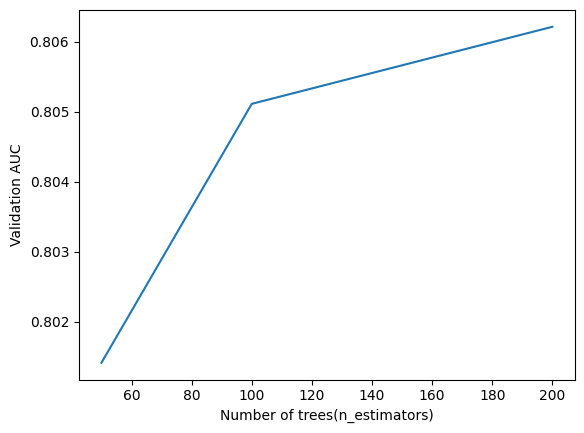

In [50]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
plt.plot(df_scores.n_estimators, df_scores.auc)
plt.xlabel('Number of trees(n_estimators)')
plt.ylabel('Validation AUC')

In [51]:
# Tune tree depth and forest size on the validation set.
scores = []

for d in [5, 10, 15]:
    for n in [100, 200]:
        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=d,
            random_state=42,
            n_jobs=-1,
        )
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        scores.append((d, n, roc_auc_score(y_val, y_pred)))

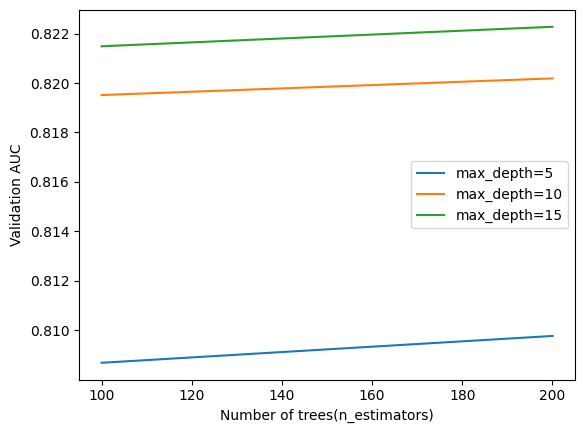

In [52]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.xlabel('Number of trees(n_estimators)')
plt.ylabel('Validation AUC')

plt.legend()

In [53]:
# Select the max_depth with the best validation AUC across the tested forest sizes.
max_depth = int(df_scores.groupby("max_depth")["auc"].max().idxmax())
print("Selected random forest max_depth:", max_depth)

Selected random forest max_depth: 15


In [54]:
# Tune the leaf size using the selected depth and a compact forest-size grid.
scores = []

for s in [1, 5, 10, 20]:
    for n in [100, 200]:
        rf = RandomForestClassifier(
            n_estimators=n,
            max_depth=max_depth,
            min_samples_leaf=s,
            random_state=42,
            n_jobs=-1,
        )
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:, 1]
        scores.append((s, n, roc_auc_score(y_val, y_pred)))

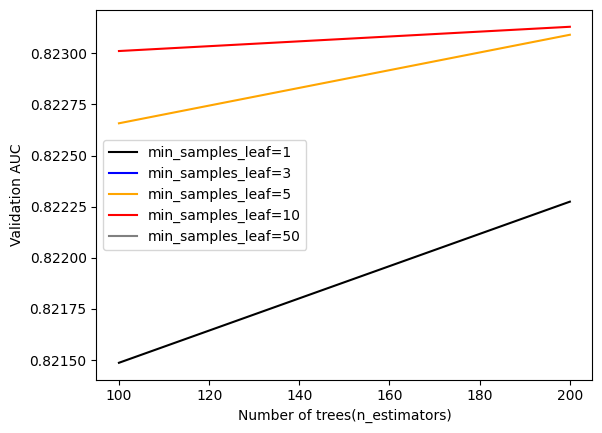

In [55]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)
plt.xlabel('Number of trees(n_estimators)')
plt.ylabel('Validation AUC')
plt.legend()

In [56]:
best_rf_row = df_scores.loc[df_scores["auc"].idxmax()]
min_samples_leaf = int(best_rf_row["min_samples_leaf"])
n_estimators = int(best_rf_row["n_estimators"])
print(
    "Selected random forest parameters:",
    {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf, "n_estimators": n_estimators},
)

Selected random forest parameters: {'max_depth': 15, 'min_samples_leaf': 10, 'n_estimators': 200}


In [57]:
# Fit the selected random forest and report its validation ROC AUC.
rf = RandomForestClassifier(
    n_estimators=n_estimators,
    max_depth=max_depth,
    min_samples_leaf=min_samples_leaf,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

In [58]:
y_pred = rf.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
auc

0.823129895795796

## XGBoost model selection and final evaluation

Tune the XGBoost hyperparameters on the training and validation sets. The selected configuration is then refit on the combined training and validation data before the held-out test evaluation.

In [59]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)
watchlist = [(dtrain, "train"), (dval, "val")]

In [60]:
# Select XGBoost hyperparameters using a compact validation grid.
results = []

etas = [0.05, 0.1, 0.3]
max_depths = [2, 3, 5]
min_child_weights = [1, 5]
num_boost_round = 200

for eta in etas:
    for max_depth in max_depths:
        for min_child_weight in min_child_weights:
            evals_result = {}
            params = {
                "eta": eta,
                "max_depth": max_depth,
                "min_child_weight": min_child_weight,
                "objective": "binary:logistic",
                "eval_metric": "auc",
                "nthread": 8,
                "seed": 42,
                "verbosity": 0,
            }
            xgb.train(
                params,
                dtrain,
                evals=watchlist,
                verbose_eval=False,
                num_boost_round=num_boost_round,
                evals_result=evals_result,
            )
            val_aucs = evals_result["val"]["auc"]
            best_iteration = int(np.argmax(val_aucs)) + 1
            best_auc = float(val_aucs[best_iteration - 1])
            results.append((eta, max_depth, min_child_weight, best_iteration, best_auc))

df_xgb_results = pd.DataFrame(
    results,
    columns=["eta", "max_depth", "min_child_weight", "best_iteration", "best_val_auc"],
).sort_values("best_val_auc", ascending=False)

display(df_xgb_results.head(10))

,eta,max_depth,min_child_weight,best_iteration,best_val_auc
9,0.10,3,5,199,0.830807
8,0.10,3,1,185,0.830611
5,0.05,5,5,200,0.830601
4,0.05,5,1,198,0.830537
11,0.10,5,5,99,0.830487
12,0.30,2,1,158,0.830467
14,0.30,3,1,74,0.830461
13,0.30,2,5,139,0.830425
15,0.30,3,5,102,0.830228
10,0.10,5,1,117,0.830160


In [61]:
#highest AUC
best_row = df_xgb_results.iloc[0]
best_row

eta                   0.100000
max_depth             3.000000
min_child_weight      5.000000
best_iteration      199.000000
best_val_auc          0.830807
Name: 9, dtype: float64

In [62]:
# Use the best validation configuration and its best boosting iteration.
best_xgb_row = df_xgb_results.iloc[0]
xgb_params = {
    "eta": float(best_xgb_row["eta"]),
    "max_depth": int(best_xgb_row["max_depth"]),
    "min_child_weight": int(best_xgb_row["min_child_weight"]),
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "nthread": 8,
    "seed": 42,
    "verbosity": 0,
}
best_num_boost_round = int(best_xgb_row["best_iteration"])

final_model = xgb.train(
    xgb_params,
    dtrain,
    evals=watchlist,
    verbose_eval=False,
    num_boost_round=best_num_boost_round,
)

val_probabilities = final_model.predict(dval)
print("Selected parameters:", xgb_params)
print("Selected boosting rounds:", best_num_boost_round)
print("Validation ROC AUC (XGBoost):", round(roc_auc_score(y_val, val_probabilities), 4))

Selected parameters: {'eta': 0.1, 'max_depth': 3, 'min_child_weight': 5, 'objective': 'binary:logistic', 'eval_metric': 'auc', 'nthread': 8, 'seed': 42, 'verbosity': 0}
Selected boosting rounds: 199
Validation ROC AUC (XGBoost): 0.8308


In [63]:
model_probabilities = {
    "Logistic Regression": lgr.predict_proba(X_val)[:, 1],
    "Tuned Logistic Regression": tuned_lgr.predict_proba(X_val)[:, 1],
    "Decision Tree": dt.predict_proba(X_val)[:, 1],
    "Tuned Decision Tree": tuned_dt.predict_proba(X_val)[:, 1],
    "Tuned Random Forest": rf.predict_proba(X_val)[:, 1],
    "Tuned XGBoost": final_model.predict(dval),
}

auc_results = pd.Series(
    {name: roc_auc_score(y_val, probabilities)
     for name, probabilities in model_probabilities.items()},
    name="Validation ROC AUC"
).sort_values(ascending=False)

display(auc_results.to_frame().round(4))

,Validation ROC AUC
Tuned XGBoost,0.8308
Tuned Logistic Regression,0.8278
Logistic Regression,0.8277
Tuned Random Forest,0.8231
Tuned Decision Tree,0.8089
Decision Tree,0.8080


In [64]:
# Refit on all development data; the test set remains untouched until this evaluation.
def train_final_model(dv, df_full_train, df_test, y_test, features, params,
                      num_boost_round=200):
    X_full_train = dv.transform(to_feature_dicts(df_full_train[features]))
    y_full_train = df_full_train["diabetes_binary"].values
    X_test = dv.transform(to_feature_dicts(df_test[features]))

    dtrain_full = xgb.DMatrix(X_full_train, label=y_full_train)
    dtest = xgb.DMatrix(X_test, label=y_test)
    model = xgb.train(
        params,
        dtrain_full,
        num_boost_round=num_boost_round,
        verbose_eval=False,
    )
    return model, dtest


features = numerical + categorical
final_model, dtest = train_final_model(
    dv,
    df_full_train,
    df_test,
    y_test,
    features,
    xgb_params,
    num_boost_round=best_num_boost_round,
)
test_probabilities = final_model.predict(dtest)
print("Test ROC AUC (XGBoost):", round(roc_auc_score(y_test, test_probabilities), 4))

Test ROC AUC (XGBoost): 0.8297


In [65]:
#saving with pickle
import pickle

output_file = "diabetes_model.bin"

with open(output_file, 'wb') as f_out:
    pickle.dump((dv, final_model), f_out)


In [ ]:
#loading the model

import pickle

with open(output_file, 'rb') as f_in:
    dv, model = pickle.load(f_in)